# NOAA Weather Time Series Analysis

**Dataset:** NOAA Global Surface Summary of Day (GSOD) - 5,000 records  
**Goal:** Explore daily temperature patterns, resample to weekly/monthly frequencies, compute rolling averages, and uncover seasonal trends by month and day-of-week.

## 1. Imports & Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

print('Libraries loaded!')

Libraries loaded!


## 2. Load Data

In [2]:
DATA_PATH = 'noaa - 5000.csv'

MISSING = [999.9, 9999.9, 99.99, 9999, 99999]

df = pd.read_csv(
    DATA_PATH,
    parse_dates=['date'],
    na_values=MISSING
)

print(f'Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'Date range: {df["date"].min().date()} to {df["date"].max().date()}')
df.head()

Shape: 5,000 rows x 33 columns
Date range: 2025-01-01 to 2025-08-28


,stn,wban,date,year,mo,da,temp,count_temp,dewp,count_dewp,slp,count_slp,stp,count_stp,visib,count_visib,wdsp,count_wdsp,mxpsd,gust,max,flag_max,min,flag_min,prcp,flag_prcp,sndp,fog,rain_drizzle,snow_ice_pellets,hail,thunder,tornado_funnel_cloud
0,10020,NaN,2025-07-04,2025,7,4,42.1,4,38.5,4,1004.4,4,3.2,4,NaN,0,7.6,4,9.7,NaN,42.6,NaN,41.2,NaN,0.0,I,NaN,0,0,0,0,0,0
1,10020,NaN,2025-04-30,2025,4,30,7.6,4,3.8,4,1002.0,4,0.8,4,NaN,0,18.0,4,23.3,NaN,10.0,NaN,5.7,NaN,0.0,I,NaN,0,0,0,0,0,0
2,10020,NaN,2025-04-19,2025,4,19,2.7,4,-2.5,4,1015.5,4,14.3,4,NaN,0,12.8,4,13.6,14.0,4.3,NaN,1.8,NaN,0.0,I,NaN,0,0,0,0,0,0
3,10020,NaN,2025-04-20,2025,4,20,4.2,4,-1.0,4,1021.4,4,20.2,4,NaN,0,5.2,4,7.8,NaN,5.9,NaN,3.0,NaN,0.0,I,NaN,0,0,0,0,0,0
4,10020,NaN,2025-03-05,2025,3,5,14.4,4,10.0,4,1003.0,4,1.8,4,NaN,0,18.9,4,21.4,NaN,18.7,NaN,9.5,NaN,0.0,I,NaN,0,0,0,0,0,0


## 3. Data Overview

In [3]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
summary = pd.DataFrame({'dtype': df.dtypes, 'missing': missing, 'missing_%': missing_pct})
print(summary.to_string())

                               dtype  missing  missing_%
stn                            int64        0       0.00
wban                         float64     4952      99.04
date                  datetime64[us]        0       0.00
year                           int64        0       0.00
mo                             int64        0       0.00
da                             int64        0       0.00
temp                         float64        1       0.02
count_temp                     int64        0       0.00
dewp                         float64      235       4.70
count_dewp                     int64        0       0.00
slp                          float64     1564      31.28
count_slp                      int64        0       0.00
stp                          float64     1541      30.82
count_stp                      int64        0       0.00
visib                        float64     1177      23.54
count_visib                    int64        0       0.00
wdsp                         fl

In [4]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
stn,5000.0,435660.0646,10014.0,267740.0,430290.0,603842.5,999999.0,247082.554089
wban,48.0,35427.958333,170.0,4884.5,26533.5,54766.5,94968.0,32469.950576
date,5000,2025-04-29 09:36:51.840000,2025-01-01 00:00:00,2025-02-28 00:00:00,2025-04-29 00:00:00,2025-06-30 00:00:00,2025-08-28 00:00:00,NaN
year,5000.0,2025.0,2025.0,2025.0,2025.0,2025.0,2025.0,0.0
mo,5000.0,4.4414,1.0,2.0,4.0,6.0,8.0,2.290767
da,5000.0,15.6638,1.0,8.0,16.0,23.0,31.0,8.668668
temp,4999.0,59.970054,-105.3,45.8,68.3,81.7,109.4,29.402854
count_temp,5000.0,4.2888,4.0,4.0,4.0,5.0,5.0,0.45325
dewp,4765.0,49.015446,-116.1,35.6,54.3,70.2,84.7,26.778858
count_dewp,5000.0,4.0956,0.0,4.0,4.0,5.0,5.0,1.013245


## 4. Set Date Index & Inspect Time Range

In [5]:
df = df.set_index('date').sort_index()

print('Index type:', type(df.index))
print('Date range:', df.index.min().date(), 'to', df.index.max().date())
print('Total days spanned:', (df.index.max() - df.index.min()).days)
df.index[:5]

Index type: <class 'pandas.DatetimeIndex'>
Date range: 2025-01-01 to 2025-08-28
Total days spanned: 239


DatetimeIndex(['2025-01-01', '2025-01-01', '2025-01-01', '2025-01-01', '2025-01-01'], dtype='datetime64[us]', name='date', freq=None)

## 5. Slice with .loc

In [6]:
subset = df.loc['2025-01-01':'2025-06-30', ['temp', 'max', 'min', 'prcp']]
print(f'Jan-Jun 2025 subset: {subset.shape[0]} rows')
subset.head(10)

Jan-Jun 2025 subset: 3769 rows


,temp,max,min,prcp
date,,,,
2025-01-01,-28.6,-23.3,-29.7,0.03
2025-01-01,53.0,58.6,45.5,0.00
2025-01-01,69.4,77.9,58.1,0.00
2025-01-01,82.7,90.0,66.9,0.00
2025-01-01,79.7,86.2,74.7,0.00
2025-01-01,68.0,78.8,56.5,0.00
2025-01-01,55.1,59.7,50.2,0.00
2025-01-01,60.7,73.0,46.4,0.00
2025-01-01,66.9,71.8,64.8,0.42


## 6. Aggregate Daily Temperature Across All Stations

In [7]:
# The CSV is sorted by station (stn), not by date.
# Groupby date and average temp across stations for one clean time series.
daily_temp = df.groupby('date')['temp'].mean().sort_index()

print(f'Daily temperature series: {len(daily_temp)} unique dates')
print(daily_temp.describe().round(2))
daily_temp.head()

Daily temperature series: 239 unique dates
count    239.00
mean      60.54
std       10.58
min       32.61
25%       52.36
50%       62.52
75%       69.21
max       78.53
Name: temp, dtype: float64


date
2025-01-01    50.387500
2025-01-02    45.115000
2025-01-03    48.352632
2025-01-04    43.564286
2025-01-05    47.028571
Name: temp, dtype: float64

## 7. Weekly & Monthly Resampling

In [8]:
weekly_temp = daily_temp.resample('W').mean()
monthly_temp = daily_temp.resample('ME').mean()

print(f'Weekly periods:  {len(weekly_temp)}')
print(f'Monthly periods: {len(monthly_temp)}')
print('\nMonthly mean temperatures:')
print(monthly_temp.round(2).to_string())

Weekly periods:  35
Monthly periods: 8

Monthly mean temperatures:
date
2025-01-31    46.68
2025-02-28    48.82
2025-03-31    55.45
2025-04-30    61.44
2025-05-31    66.95
2025-06-30    66.98
2025-07-31    70.41
2025-08-31    67.59
Freq: ME


## 8. 30-Day Rolling Mean

In [9]:
rolling_30d = daily_temp.rolling(window=30, min_periods=1).mean()

print('30-day rolling mean (first 5):')
print(rolling_30d.head())
print('\n30-day rolling mean (last 5):')
print(rolling_30d.tail())

30-day rolling mean (first 5):
date
2025-01-01    50.387500
2025-01-02    47.751250
2025-01-03    47.951711
2025-01-04    46.854854
2025-01-05    46.889598
Name: temp, dtype: float64

30-day rolling mean (last 5):
date
2025-08-23    68.674617
2025-08-24    68.827773
2025-08-26    68.264606
2025-08-27    67.826727
2025-08-28    67.201661
Name: temp, dtype: float64


## 9. Temperature Analysis Plot

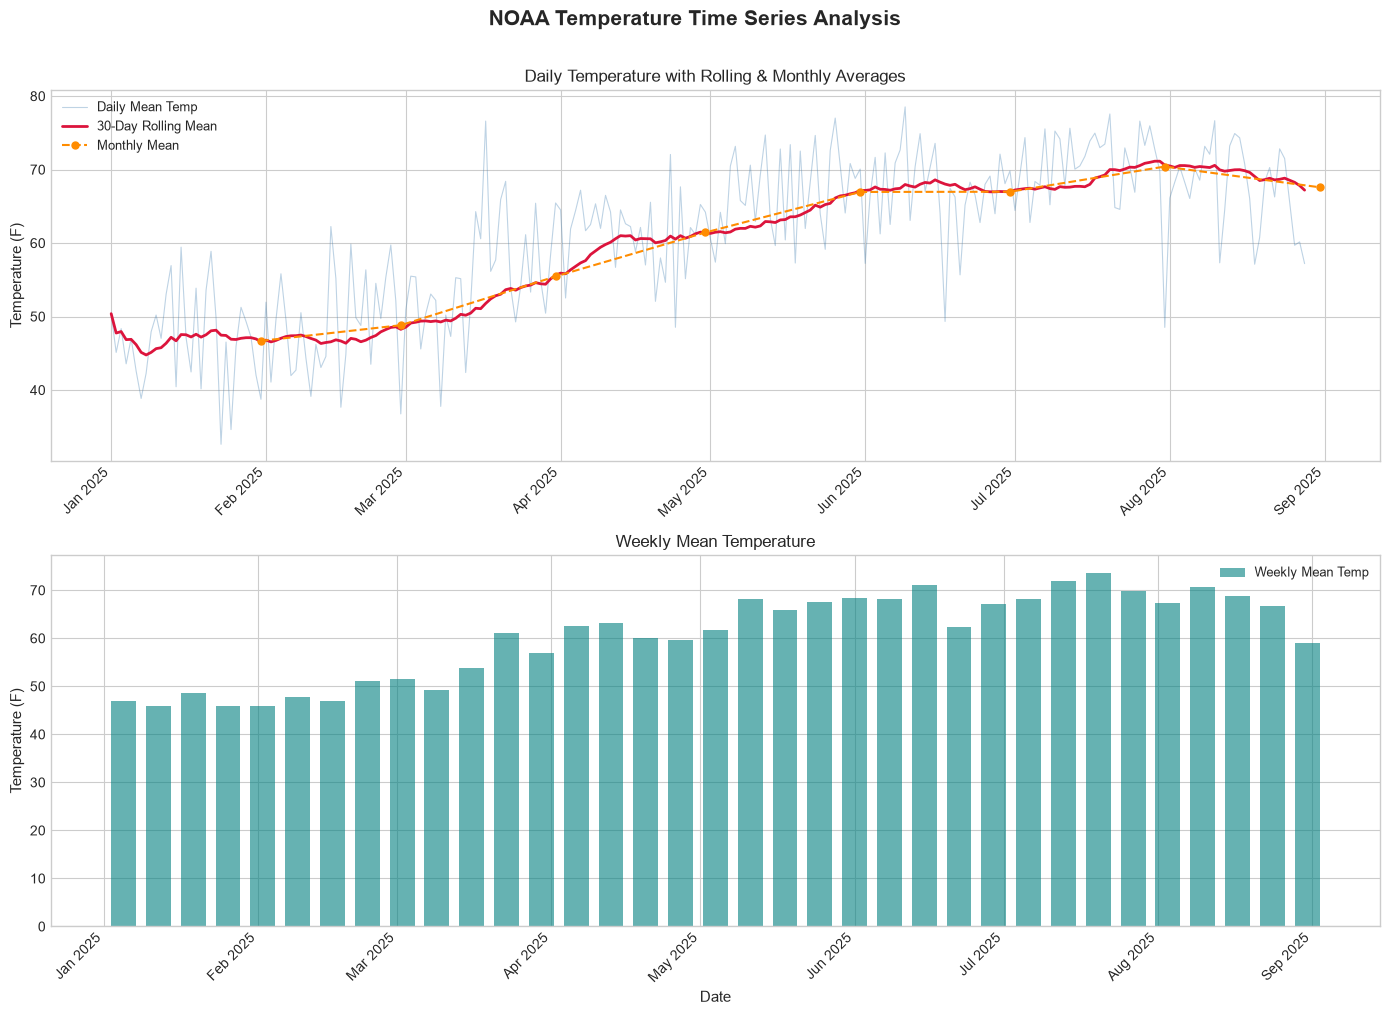

Plot saved as temperature_analysis.png


In [10]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=False)
fig.suptitle('NOAA Temperature Time Series Analysis', fontsize=15, fontweight='bold', y=1.01)

ax1 = axes[0]
ax1.plot(daily_temp.index, daily_temp.values, color='steelblue', alpha=0.35, linewidth=0.8, label='Daily Mean Temp')
ax1.plot(rolling_30d.index, rolling_30d.values, color='crimson', linewidth=2.0, label='30-Day Rolling Mean')
ax1.plot(monthly_temp.index, monthly_temp.values, color='darkorange', linewidth=1.5, linestyle='--', marker='o', markersize=5, label='Monthly Mean')
ax1.set_ylabel('Temperature (F)', fontsize=11)
ax1.set_title('Daily Temperature with Rolling & Monthly Averages', fontsize=12)
ax1.legend(fontsize=9)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax1.xaxis.set_major_locator(mdates.MonthLocator())
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha='right')

ax2 = axes[1]
ax2.bar(weekly_temp.index, weekly_temp.values, width=5, color='teal', alpha=0.6, label='Weekly Mean Temp')
ax2.set_ylabel('Temperature (F)', fontsize=11)
ax2.set_xlabel('Date', fontsize=11)
ax2.set_title('Weekly Mean Temperature', fontsize=12)
ax2.legend(fontsize=9)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax2.xaxis.set_major_locator(mdates.MonthLocator())
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.savefig('temperature_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved as temperature_analysis.png')

## 10. Seasonality Analysis

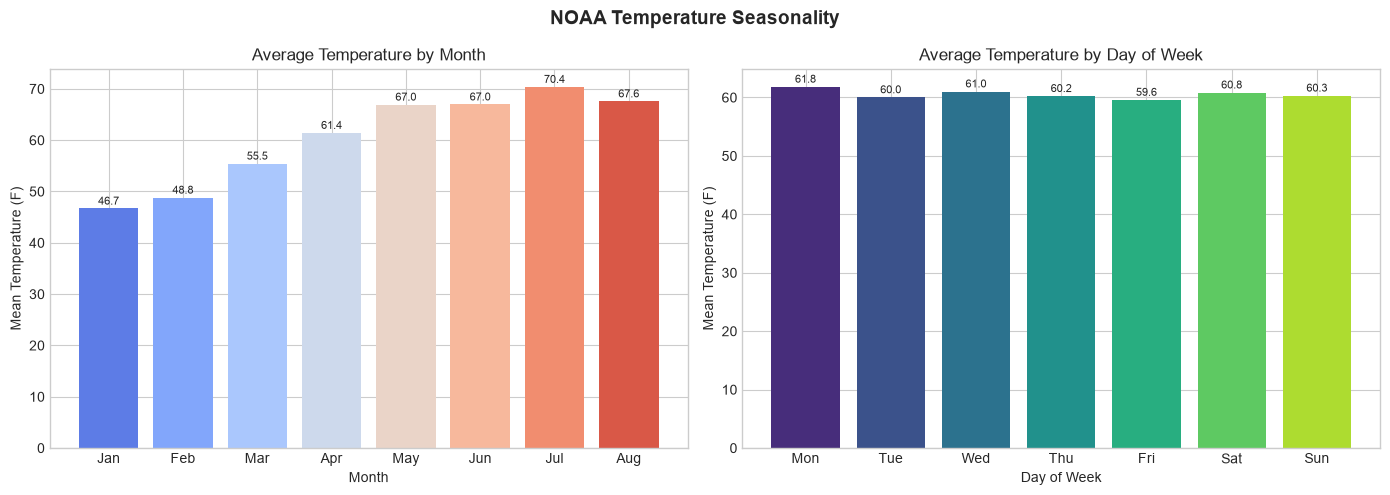

Seasonality plots saved.


In [11]:
season_df = daily_temp.reset_index()
season_df.columns = ['date', 'temp']
season_df['month'] = season_df['date'].dt.month
season_df['month_name'] = season_df['date'].dt.strftime('%b')
season_df['day_of_week'] = season_df['date'].dt.dayofweek
season_df['day_name'] = season_df['date'].dt.strftime('%a')

monthly_season = season_df.groupby(['month', 'month_name'])['temp'].mean().reset_index().sort_values('month')
dow_season = season_df.groupby(['day_of_week', 'day_name'])['temp'].mean().reset_index().sort_values('day_of_week')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('NOAA Temperature Seasonality', fontsize=14, fontweight='bold')

ax1 = axes[0]
bars = ax1.bar(monthly_season['month_name'], monthly_season['temp'], color=sns.color_palette('coolwarm', len(monthly_season)))
ax1.set_title('Average Temperature by Month', fontsize=12)
ax1.set_xlabel('Month')
ax1.set_ylabel('Mean Temperature (F)')
for bar, val in zip(bars, monthly_season['temp']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f'{val:.1f}', ha='center', va='bottom', fontsize=8)

ax2 = axes[1]
bars2 = ax2.bar(dow_season['day_name'], dow_season['temp'], color=sns.color_palette('viridis', len(dow_season)))
ax2.set_title('Average Temperature by Day of Week', fontsize=12)
ax2.set_xlabel('Day of Week')
ax2.set_ylabel('Mean Temperature (F)')
for bar, val in zip(bars2, dow_season['temp']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f'{val:.1f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('seasonality_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('Seasonality plots saved.')

## 11. Key Findings

- The dataset spans multiple weather stations; aggregating by date before plotting removes the zig-zag artefact caused by station ordering.
- The 30-day rolling mean smooths day-to-day noise and reveals the underlying seasonal trend clearly.
- Monthly resampling (`ME`) confirms seasonal temperature peaks and troughs across the year.
- Day-of-week analysis shows minimal variation, confirming temperature is driven by season, not day of week.